In [23]:
# ==============================================================================
# 📦 CELL 1: INSTALL REQUIRED PACKAGES (RUN FIRST ON COLAB / KAGGLE)
# ==============================================================================
try:
    get_ipython().system('pip install -q -U timm torchvision scikit-learn seaborn pandas opencv-python matplotlib tqdm huggingface_hub')
    print("✅ Successfully installed dependencies via pip!")
except Exception:
    import sys, subprocess
    pkgs = ["timm", "torchvision", "scikit-learn", "seaborn", "pandas", "opencv-python", "matplotlib", "tqdm", "huggingface_hub"]
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "-U"] + pkgs)
    print("✅ Successfully installed dependencies via subprocess!")


✅ Successfully installed dependencies via pip!


# 🚀 03. Optimized Unimodal Vision Baseline: DINOv3 + Classification Head

**Project:** Durian Ripeness Classification via Cross-Modal Knowledge Distillation (Durian Ripeness CMKD)  
**Model:** Meta DINOv3 ViT-Base (`vit_base_patch16_dinov3.lvd1689m` via `timm`) + Classification Head  
**Checkpoint Path:** `/content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint`  
**Test Results Path:** `/content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results`

---

### 🌟 Key Engineering Mechanisms & Checkpoint Design:
1. **Smart Pretrained DINOv3 Weight Caching & Non-Overwriting Checkpoint Separation:**
   - **`dinov3_pretrained_raw_weights.pt`**: Saves the original downloaded DINOv3 weights directly to Google Drive on the first run. Subsequent Colab sessions load directly from Drive (`pretrained=False` + `load_state_dict`) to bypass HuggingFace Hub downloads.
   - **`dinov3_classification_head_best.pt`**: Saves **only** the trained Classification Head weights separately so it never collides with or overwrites the DINOv3 backbone files.
   - **`dinov3_finetuned_backbone_best.pt`**: Saves the fine-tuned DINOv3 feature extractor backbone separately for downstream Multi-Modal Fusion.
   - **`dinov3_full_model_best.pt`** & **`dinov3_full_model_last.pt`**: Full end-to-end training states (backbone + head + optimizer + scheduler + history).
   - **`dinov3_periodic_epoch_XX.pt`**: Periodic snapshots saved every 5 epochs.
2. **End-to-End Differential LR + 5-Epoch Linear Warmup (Matching ConvNeXtV2 Recipe):**
   - **DINOv3 Backbone (`vit_base_patch16_dinov3.lvd1689m`):** Fine-tuned end-to-end from Epoch 1 with a conservative LR ($2 \times 10^{-5}$) and 5-epoch linear warmup so self-attention blocks adapt smoothly to durian spine textures.
   - **Direct Linear Classification Head (`LayerNorm -> Dropout(0.3) -> Linear(768, 3)`):** Trained at $5 \times 10^{-4}$ for direct gradient flow without multi-layer bottleneck attenuation.
3. **Clean Multiprocessing DataLoader (`persistent_workers=True`) & Anti-Overfitting Boosters:**
   - Eliminates Python 3.13 Colab `_MultiProcessingDataLoaderIter.__del__` `AssertionError` by keeping persistent workers alive across epochs.
   - High-resolution **$384 \times 384$** (divisible by patch size $16 \rightarrow 24 \times 24 = 576$ spatial tokens) + **L-Channel CLAHE**.
   - **Stochastic Depth (`drop_path_rate = 0.2`)**, **Head Dropout (`0.3`)**, **Decoupled Weight Decay (`1e-2`)**, **Label Smoothing (`0.05`)**, **Class-Weighted Cross-Entropy**, and **Delayed Mixup & CutMix** (enabled after Epoch 10).
   - **Early Stopping (`patience = 10`, active after `min_epochs = 8`)** monitoring Validation Loss + **3-View Test-Time Augmentation (TTA)** & **Fruit-Level Soft Voting**.

In [24]:
# 2. Import libraries and configure compute environment
import gc
import json
import math
import os
import random
import sys
import time
import warnings
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)

# Fix random seeds for Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Configure compute device (GPU / MPS / CPU)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu"))
print(f"✅ Active compute device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"   • GPU Name: {torch.cuda.get_device_name(0)}")
    print(f"   • VRAM    : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")


✅ Active compute device: cuda
   • GPU Name: NVIDIA L4
   • VRAM    : 22.03 GB


In [25]:
# 3. Mount Google Drive and configure Data, Checkpoint & Results paths
#    All .pt files have distinct, descriptive filenames to prevent any overwriting!
IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

def find_project_root() -> str:
    cur = os.path.abspath(".")
    for _ in range(6):
        if os.path.isdir(os.path.join(cur, "data")) or os.path.isdir(os.path.join(cur, "workspaces")):
            return cur
        parent = os.path.dirname(cur)
        if parent == cur:
            break
        cur = parent
    return os.path.abspath("../../..")

if IN_COLAB:
    from google.colab import drive
    if not os.path.exists("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    print("✅ Successfully mounted Google Drive at /content/drive")
    
    DATA_SPLIT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/split_data"
    DATA_FINAL_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/data/final"
    CHECKPOINT_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint"
    RESULTS_DIR = "/content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results"
    DEMO_CACHE_DIR = "/content/colab_temp_cache/demo_vision_dinov3"
else:
    PROJECT_ROOT = find_project_root()
    DATA_SPLIT_DIR = os.path.join(PROJECT_ROOT, "data", "split_data")
    DATA_FINAL_DIR = os.path.join(PROJECT_ROOT, "data", "final")
    CHECKPOINT_DIR = os.path.join(PROJECT_ROOT, "baselines", "DINOv3_classification_head", "outputs", "checkpoint")
    RESULTS_DIR = os.path.join(PROJECT_ROOT, "baselines", "DINOv3_classification_head", "outputs", "results")
    DEMO_CACHE_DIR = os.path.join(PROJECT_ROOT, ".demo_vision_cache")

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# --- DISTINCT CHECKPOINT FILENAMES (NO OVERWRITING BETWEEN BACKBONE & HEAD) ---
RAW_PRETRAINED_BACKBONE_PATH = os.path.join(CHECKPOINT_DIR, "dinov3_pretrained_raw_weights.pt")
FINETUNED_BACKBONE_BEST_PATH = os.path.join(CHECKPOINT_DIR, "dinov3_finetuned_backbone_best.pt")
CLASSIFICATION_HEAD_BEST_PATH = os.path.join(CHECKPOINT_DIR, "dinov3_classification_head_best.pt")
BEST_FULL_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "dinov3_full_model_best.pt")
LAST_FULL_CHECKPOINT_PATH = os.path.join(CHECKPOINT_DIR, "dinov3_full_model_last.pt")

print(f"\n[PATH & CHECKPOINT CONFIGURATION]")
print(f"  • Final Data Directory          : {DATA_FINAL_DIR}")
print(f"  • Checkpoint Directory          : {CHECKPOINT_DIR}")
print(f"  • Results Directory             : {RESULTS_DIR}")
print(f"  • Raw Pretrained DINOv3 Cache   : {RAW_PRETRAINED_BACKBONE_PATH}")
print(f"  • Fine-tuned DINOv3 Backbone    : {FINETUNED_BACKBONE_BEST_PATH}")
print(f"  • Trained Classification Head   : {CLASSIFICATION_HEAD_BEST_PATH}")
print(f"  • Best Full Model Checkpoint    : {BEST_FULL_CHECKPOINT_PATH}")


✅ Successfully mounted Google Drive at /content/drive

[PATH & CHECKPOINT CONFIGURATION]
  • Final Data Directory          : /content/drive/MyDrive/durian-ripeness-cmkd/data/final
  • Checkpoint Directory          : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint
  • Results Directory             : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results
  • Raw Pretrained DINOv3 Cache   : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint/dinov3_pretrained_raw_weights.pt
  • Fine-tuned DINOv3 Backbone    : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint/dinov3_finetuned_backbone_best.pt
  • Trained Classification Head   : /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint/dinov3_classification_head_best.pt
  • Best Full Model Checkpoint    : /content/drive/MyDrive/durian-ripeness-cmkd/b

In [26]:
# 4. Scan dataset splits and compute Class Weights for Class Imbalance
RIPENESS_ORDER = ["Unripe", "Ripe", "Overripe"]
LABEL_TO_IDX = {name: idx for idx, name in enumerate(RIPENESS_ORDER)}
IDX_TO_LABEL = {idx: name for name, idx in LABEL_TO_IDX.items()}

def parse_label_from_filename(filename: str) -> Optional[str]:
    fn = filename.lower()
    if "_unripe" in fn or "-un" in fn or "_immature" in fn:
        return "Unripe"
    elif "_overripe" in fn or "-or" in fn or "_senescent" in fn:
        return "Overripe"
    elif "_ripe" in fn or "-ri" in fn or "_mature" in fn:
        return "Ripe"
    return None

def collect_split_images(data_split_dir: str, data_final_dir: str) -> Dict[str, List[Dict]]:
    splits_data = {"train": [], "val": [], "test": []}
    used_source = None
    
    # 1. Scan from data/final/
    if os.path.isdir(data_final_dir):
        for sp in ["train", "val", "test"]:
            actual_sp_dir = os.path.join(data_final_dir, "valid" if (sp == "val" and not os.path.isdir(os.path.join(data_final_dir, "val"))) else sp, "rgb")
            if os.path.isdir(actual_sp_dir):
                files = [f for f in os.listdir(actual_sp_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                for f in files:
                    lbl = parse_label_from_filename(f)
                    if lbl:
                        splits_data[sp].append({
                            "filepath": os.path.join(actual_sp_dir, f),
                            "filename": f,
                            "label": lbl,
                            "label_idx": LABEL_TO_IDX[lbl],
                            "split": sp
                        })
        if sum(len(v) for v in splits_data.values()) > 0:
            used_source = "data/final"

    # 2. Scan from data/split_data/
    if sum(len(v) for v in splits_data.values()) == 0 and os.path.isdir(data_split_dir):
        for sp in ["train", "val", "test"]:
            sp_dir = os.path.join(data_split_dir, sp, "dataset_clean_rgb")
            if os.path.isdir(sp_dir):
                files = [f for f in os.listdir(sp_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
                for f in files:
                    lbl = parse_label_from_filename(f)
                    if lbl:
                        splits_data[sp].append({
                            "filepath": os.path.join(sp_dir, f),
                            "filename": f,
                            "label": lbl,
                            "label_idx": LABEL_TO_IDX[lbl],
                            "split": sp
                        })
        if sum(len(v) for v in splits_data.values()) > 0:
            used_source = "data/split_data"

    print(f"[*] Detected data source: {used_source or 'No real images found yet'}")
    return splits_data

image_splits = collect_split_images(DATA_SPLIT_DIR, DATA_FINAL_DIR)
total_images = sum(len(v) for v in image_splits.values())

# Fallback demo cache if environment is empty
if total_images == 0:
    print(f"⚠️ Creating synthetic demo image set at {DEMO_CACHE_DIR}...")
    os.makedirs(DEMO_CACHE_DIR, exist_ok=True)
    for sp, count in [("train", 12), ("val", 6), ("test", 6)]:
        sp_dir = os.path.join(DEMO_CACHE_DIR, sp)
        os.makedirs(sp_dir, exist_ok=True)
        for i in range(count):
            lbl = RIPENESS_ORDER[i % 3]
            fname = f"durian_{i+1:03d}_A_{lbl}_TOP.jpg"
            fpath = os.path.join(sp_dir, fname)
            if not os.path.exists(fpath):
                arr = np.random.randint(40, 180, (384, 384, 3), dtype=np.uint8)
                cv2.circle(arr, (192, 192), 120, (50, 120, 40) if lbl=="Unripe" else ((30, 140, 180) if lbl=="Ripe" else (20, 80, 160)), -1)
                cv2.imwrite(fpath, arr)
            image_splits[sp].append({
                "filepath": fpath,
                "filename": fname,
                "label": lbl,
                "label_idx": LABEL_TO_IDX[lbl],
                "split": sp
            })

# Image distribution statistics
summary_records = []
for sp in ["train", "val", "test"]:
    df_sp = pd.DataFrame(image_splits[sp])
    if len(df_sp) > 0:
        counts = df_sp["label"].value_counts().to_dict()
        summary_records.append({
            "Split": sp,
            "Unripe": counts.get("Unripe", 0),
            "Ripe": counts.get("Ripe", 0),
            "Overripe": counts.get("Overripe", 0),
            "Total Images": len(df_sp)
        })
df_summary = pd.DataFrame(summary_records)
print(f"\n📊 [IMAGE DISTRIBUTION ACROSS SPLITS]")
print(df_summary.to_string(index=False))

# --- COMPUTE CLASS WEIGHTS FROM TRAIN SPLIT ---
df_train = pd.DataFrame(image_splits["train"])
train_counts = [df_train["label"].value_counts().get(c, 1) for c in RIPENESS_ORDER]
total_train = sum(train_counts)

# Inverse class-frequency weighting formula: w_c = N / (K * N_c)
class_weights_val = [total_train / (len(RIPENESS_ORDER) * count) for count in train_counts]
CLASS_WEIGHTS = torch.tensor(class_weights_val, dtype=torch.float).to(DEVICE)

print(f"\n⚖️ [CLASS WEIGHTS TO HANDLE IMBALANCE]")
for name, count, w in zip(RIPENESS_ORDER, train_counts, class_weights_val):
    print(f"  • {name:<9}: {count:>4} images -->  Weight: {w:.3f}")


[*] Detected data source: data/final

📊 [IMAGE DISTRIBUTION ACROSS SPLITS]
Split  Unripe  Ripe  Overripe  Total Images
train     335   562       600          1497
  val      60   102       120           282
 test      60   114       124           298

⚖️ [CLASS WEIGHTS TO HANDLE IMBALANCE]
  • Unripe   :  335 images -->  Weight: 1.490
  • Ripe     :  562 images -->  Weight: 0.888
  • Overripe :  600 images -->  Weight: 0.832


In [27]:
# 5. High-resolution 384x384 preprocessing (24x24 Patch16 grid), L-channel CLAHE & Delayed Mixup/CutMix
class CLAHETransform:
    """Apply standard CLAHE on the L (LAB) channel to enhance spine-groove micro-textures."""
    def __init__(self, clip_limit: float = 2.0, tile_grid_size: Tuple[int, int] = (8, 8)):
        self.clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)

    def __call__(self, img: Image.Image) -> Image.Image:
        np_img = np.array(img)
        lab = cv2.cvtColor(np_img, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        l_clahe = self.clahe.apply(l)
        enhanced_lab = cv2.merge((l_clahe, a, b))
        enhanced_rgb = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)
        return Image.fromarray(enhanced_rgb)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# 384x384 is divisible by Patch16 (384 / 16 = 24x24 = 576 patches) for clean DINOv3 RoPE/Positional encoding
IMAGE_SIZE = 384

def get_train_transforms(image_size: int = IMAGE_SIZE) -> transforms.Compose:
    return transforms.Compose([
        CLAHETransform(clip_limit=2.0, tile_grid_size=(8, 8)),
        transforms.RandomResizedCrop(image_size, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.2),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

def get_eval_transforms(image_size: int = IMAGE_SIZE) -> transforms.Compose:
    return transforms.Compose([
        CLAHETransform(clip_limit=2.0, tile_grid_size=(8, 8)),
        transforms.Resize(int(image_size * 1.08)),
        transforms.CenterCrop(image_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
    ])

def apply_mixup(images: torch.Tensor, labels: torch.Tensor, alpha: float = 0.2) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, float]:
    """Gentle Mixup (alpha=0.2) to smooth decision boundaries without heavy label noise."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    batch_size = images.size(0)
    index = torch.randperm(batch_size).to(images.device)
    mixed_images = lam * images + (1 - lam) * images[index]
    return mixed_images, labels, labels[index], lam

def apply_cutmix(images: torch.Tensor, labels: torch.Tensor, alpha: float = 0.2) -> Tuple[torch.Tensor, torch.Tensor, torch.Tensor, float]:
    """Gentle CutMix so DINOv3 self-attention attends across distributed local spine patches."""
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    batch_size, _, H, W = images.size()
    index = torch.randperm(batch_size).to(images.device)
    
    cut_rat = np.sqrt(1.0 - lam)
    cut_w = int(W * cut_rat)
    cut_h = int(H * cut_rat)
    cx = np.random.randint(W)
    cy = np.random.randint(H)
    
    bbx1 = np.clip(cx - cut_w // 2, 0, W)
    bby1 = np.clip(cy - cut_h // 2, 0, H)
    bbx2 = np.clip(cx + cut_w // 2, 0, W)
    bby2 = np.clip(cy + cut_h // 2, 0, H)
    
    mixed_images = images.clone()
    mixed_images[:, :, bby1:bby2, bbx1:bbx2] = images[index, :, bby1:bby2, bbx1:bbx2]
    lam = 1.0 - ((bbx2 - bbx1) * (bby2 - bby1) / (W * H))
    return mixed_images, labels, labels[index], float(lam)


In [28]:
# 6. PyTorch Dataset and DataLoaders (with persistent_workers=True to fix Python 3.13 multiprocessing AssertionError)
class DurianRipenessDataset(Dataset):
    def __init__(self, records: List[Dict], transform: Optional[transforms.Compose] = None):
        self.records = records
        self.transform = transform

    def __len__(self) -> int:
        return len(self.records)

    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, int, str]:
        item = self.records[idx]
        with Image.open(item["filepath"]) as img:
            rgb_img = img.convert("RGB")
        
        tensor_img = self.transform(rgb_img) if self.transform else transforms.ToTensor()(rgb_img)
        return tensor_img, item["label_idx"], item["filename"]

BATCH_SIZE = 16 if torch.cuda.is_available() else 4
# NUM_WORKERS = 2 + persistent_workers = True prevents Python 3.13 Colab _MultiProcessingDataLoaderIter.__del__ AssertionError
NUM_WORKERS = 2 if torch.cuda.is_available() else 0

train_dataset = DurianRipenessDataset(image_splits["train"], transform=get_train_transforms(IMAGE_SIZE))
val_dataset = DurianRipenessDataset(image_splits["val"], transform=get_eval_transforms(IMAGE_SIZE))
test_dataset = DurianRipenessDataset(image_splits["test"], transform=get_eval_transforms(IMAGE_SIZE))

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0),
    drop_last=(len(train_dataset) > BATCH_SIZE)
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
    persistent_workers=(NUM_WORKERS > 0)
)

print(f"✅ DataLoaders ready at resolution {IMAGE_SIZE}x{IMAGE_SIZE} (num_workers={NUM_WORKERS}, persistent_workers={NUM_WORKERS > 0}):")
print(f"  • Train: {len(train_dataset)} images ({len(train_loader)} batches)")
print(f"  • Val  : {len(val_dataset)} images ({len(val_loader)} batches)")
print(f"  • Test : {len(test_dataset)} images ({len(test_loader)} batches)")


✅ DataLoaders ready at resolution 384x384 (num_workers=2, persistent_workers=True):
  • Train: 1497 images (93 batches)
  • Val  : 282 images (18 batches)
  • Test : 298 images (19 batches)


In [29]:
# 7. Initialize DINOv3 Backbone + Classification Head with Smart Drive Caching
#    - Saves raw DINOv3 weights to `dinov3_pretrained_raw_weights.pt` on first download.
#    - Reloads from Drive on future runs to save download time.
#    - Never overwrites `dinov3_classification_head_best.pt` or `dinov3_finetuned_backbone_best.pt`.

DINOV3_CANDIDATE_MODELS = [
    "vit_base_patch16_dinov3.lvd1689m",
    "convnext_base.dinov3_lvd1689m",
    "vit_base_patch14_dinov2.lvd142m"
]

class DINOv3ClassificationModel(nn.Module):
    def __init__(
        self,
        num_classes: int = 3,
        drop_path_rate: float = 0.2,
        head_dropout: float = 0.3,
        raw_cache_path: str = RAW_PRETRAINED_BACKBONE_PATH
    ):
        super().__init__()
        self.backbone = None
        self.model_name = None

        # 1. Check if raw pretrained DINOv3 weights are already cached in Google Drive
        if os.path.isfile(raw_cache_path):
            try:
                print(f"[*] ⚡ Found cached DINOv3 pretrained weights in Drive: {raw_cache_path}")
                cached_payload = torch.load(raw_cache_path, map_location="cpu")
                cached_arch = cached_payload.get("model_name", DINOV3_CANDIDATE_MODELS[0])
                create_kwargs = {"pretrained": False, "num_classes": 0, "drop_path_rate": drop_path_rate}
                if cached_arch.startswith("vit_"):
                    create_kwargs["dynamic_img_size"] = True
                self.backbone = timm.create_model(cached_arch, **create_kwargs)
                self.backbone.load_state_dict(cached_payload["backbone_state_dict"], strict=False)
                self.model_name = cached_arch
                print(f"✅ Loaded DINOv3 ('{self.model_name}') from Drive cache without internet download!")
            except Exception as e:
                print(f"⚠️ Cached DINOv3 load warning ({e}), falling back to Hub download...")
                self.backbone = None

        # 2. If not cached yet, download from HuggingFace / timm and immediately cache to Drive
        if self.backbone is None:
            for candidate in DINOV3_CANDIDATE_MODELS:
                try:
                    print(f"[*] Downloading pre-trained DINOv3 weights: '{candidate}'...")
                    create_kwargs = {"pretrained": True, "num_classes": 0, "drop_path_rate": drop_path_rate}
                    if candidate.startswith("vit_"):
                        create_kwargs["dynamic_img_size"] = True
                    self.backbone = timm.create_model(candidate, **create_kwargs)
                    self.model_name = candidate
                    torch.save({
                        "model_name": self.model_name,
                        "backbone_state_dict": self.backbone.state_dict(),
                        "feature_dim": self.backbone.num_features,
                        "saved_at": time.strftime("%Y-%m-%d %H:%M:%S")
                    }, raw_cache_path)
                    print(f"💾 Cached raw DINOv3 weights to Drive at: {raw_cache_path}")
                    break
                except Exception as e:
                    print(f"⚠️ Could not load '{candidate}': {e}")

        if self.backbone is None:
            raise RuntimeError("Failed to initialize DINOv3 backbone. Please ensure `timm` is updated (`pip install -U timm`).")

        self.num_features = self.backbone.num_features  # 768 for ViT-Base / 1024 for ConvNeXt-Base

        # 3. Direct Regularized Classification Head (LayerNorm + Dropout + Linear) for clean gradient flow
        self.classification_head = nn.Sequential(
            nn.LayerNorm(self.num_features),
            nn.Dropout(p=head_dropout),
            nn.Linear(self.num_features, num_classes)
        )

    def forward_features(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)

    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        features = self.forward_features(x)
        logits = self.classification_head(features)
        return logits, features

model = DINOv3ClassificationModel(
    num_classes=len(RIPENESS_ORDER),
    drop_path_rate=0.2,
    head_dropout=0.3,
    raw_cache_path=RAW_PRETRAINED_BACKBONE_PATH
).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
head_params = sum(p.numel() for p in model.classification_head.parameters())
print(f"✅ Initialized DINOv3 ('{model.model_name}') + Classification Head:")
print(f"   • Total Params : {total_params / 1e6:.2f} M (Feature Dim: {model.num_features})")
print(f"   • Head Params  : {head_params / 1e3:.2f} K")


[*] ⚡ Found cached DINOv3 pretrained weights in Drive: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint/dinov3_pretrained_raw_weights.pt
✅ Loaded DINOv3 ('vit_base_patch16_dinov3.lvd1689m') from Drive cache without internet download!
✅ Initialized DINOv3 ('vit_base_patch16_dinov3.lvd1689m') + Classification Head:
   • Total Params : 85.65 M (Feature Dim: 768)
   • Head Params  : 3.84 K


In [30]:
# 8. Configure Differential Learning Rate, 5-Epoch Linear Warmup, Cosine Scheduler & Class-Weighted Loss
# --- DIFFERENTIAL LEARNING RATES FOR DINOV3 BACKBONE & CLASSIFICATION HEAD ---
BACKBONE_LR = 2e-5   # Effective fine-tuning LR for DINOv3 ViT-Base with 5-epoch warmup
HEAD_LR = 5e-4       # Fast adaptation LR for the Classification Head
WEIGHT_DECAY = 1e-2  # Decoupled weight decay for 2D+ weight matrices

decay_backbone, no_decay_backbone = [], []
decay_head, no_decay_head = [], []

for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    is_no_decay = (
        param.ndim <= 1
        or name.endswith(".bias")
        or "norm" in name.lower()
        or "cls_token" in name.lower()
        or "pos_embed" in name.lower()
        or "reg_token" in name.lower()
        or "gamma" in name.lower()
    )
    if "classification_head" in name:
        if is_no_decay:
            no_decay_head.append(param)
        else:
            decay_head.append(param)
    else:
        if is_no_decay:
            no_decay_backbone.append(param)
        else:
            decay_backbone.append(param)

optimizer_grouped_parameters = [
    {"params": decay_backbone, "weight_decay": WEIGHT_DECAY, "lr": BACKBONE_LR},
    {"params": no_decay_backbone, "weight_decay": 0.0, "lr": BACKBONE_LR},
    {"params": decay_head, "weight_decay": WEIGHT_DECAY, "lr": HEAD_LR},
    {"params": no_decay_head, "weight_decay": 0.0, "lr": HEAD_LR},
]

optimizer = torch.optim.AdamW(optimizer_grouped_parameters, eps=1e-8)

EPOCHS = 40
WARMUP_EPOCHS = 5
SAVE_EVERY_EPOCHS = 5  # Periodic checkpointing interval

# Combined scheduler: 5 Epochs Linear Warmup + Cosine Annealing
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, end_factor=1.0, total_iters=WARMUP_EPOCHS)
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=(EPOCHS - WARMUP_EPOCHS), eta_min=1e-6)
scheduler = torch.optim.lr_scheduler.SequentialLR(
    optimizer,
    schedulers=[warmup_scheduler, cosine_scheduler],
    milestones=[WARMUP_EPOCHS]
)

# Loss function with Class Weights and light 0.05 Label Smoothing
criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS, label_smoothing=0.05)

print("✅ Optimizer & Differential LR Schedule configured:")
print(f"  • DINOv3 Backbone LR : {BACKBONE_LR} (End-to-End Fine-Tuning with 5-Epoch Warmup)")
print(f"  • Head LR            : {HEAD_LR} (Fast adaptation)")
print(f"  • Warmup             : First {WARMUP_EPOCHS} epochs + Cosine Annealing")
print(f"  • Periodic Save      : Every {SAVE_EVERY_EPOCHS} epochs")
print(f"  • Loss               : CrossEntropyLoss (Class Weights + Label Smoothing 0.05)")


✅ Optimizer & Differential LR Schedule configured:
  • DINOv3 Backbone LR : 2e-05 (End-to-End Fine-Tuning with 5-Epoch Warmup)
  • Head LR            : 0.0005 (Fast adaptation)
  • Warmup             : First 5 epochs + Cosine Annealing
  • Periodic Save      : Every 5 epochs
  • Loss               : CrossEntropyLoss (Class Weights + Label Smoothing 0.05)


In [31]:
# 9. Non-Overwriting Checkpoint Management, Periodic Saving & Early Stopping Anti-Overfitting
FORCE_FRESH_START = True  # SET TRUE TO START CLEAN TRAINING; SET FALSE TO RESUME FROM LAST CHECKPOINT

class EarlyStopping:
    """Stop training automatically when Val Macro-F1 fails to improve for 'patience' consecutive epochs after 'min_epochs'."""
    def __init__(self, patience: int = 10, min_delta: float = 1e-4, min_epochs: int = 8):
        self.patience = patience
        self.min_delta = min_delta
        self.min_epochs = min_epochs
        self.counter = 0
        self.best_score = -1.0
        self.early_stop = False

    def __call__(self, current_val_f1: float, epoch: int) -> bool:
        if current_val_f1 > (self.best_score + self.min_delta):
            self.best_score = current_val_f1
            self.counter = 0
            return True  # Improved -> Save best checkpoints
        else:
            if epoch >= self.min_epochs:
                self.counter += 1
                if self.counter >= self.patience:
                    self.early_stop = True
            return False

def save_full_checkpoint(
    model_obj: DINOv3ClassificationModel,
    state_dict_optimizer,
    state_dict_scheduler,
    epoch: int,
    best_val_loss: float,
    best_val_f1: float,
    best_epoch: int,
    history: Dict,
    save_path: str
):
    payload = {
        "epoch": epoch,
        "best_epoch": best_epoch,
        "model_state_dict": model_obj.state_dict(),
        "backbone_state_dict": model_obj.backbone.state_dict(),
        "classification_head_state_dict": model_obj.classification_head.state_dict(),
        "optimizer_state_dict": state_dict_optimizer,
        "scheduler_state_dict": state_dict_scheduler,
        "best_val_loss": best_val_loss,
        "best_val_f1": best_val_f1,
        "history": history,
        "model_architecture": model_obj.model_name,
        "feature_dim": model_obj.num_features,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
    }
    torch.save(payload, save_path)

def save_separate_backbone_and_head(
    model_obj: DINOv3ClassificationModel,
    epoch: int,
    val_loss: float,
    val_f1: float,
    backbone_save_path: str = FINETUNED_BACKBONE_BEST_PATH,
    head_save_path: str = CLASSIFICATION_HEAD_BEST_PATH
):
    """Save fine-tuned DINOv3 backbone and Classification Head into 2 distinct .pt files so they never overwrite each other."""
    assert os.path.abspath(backbone_save_path) != os.path.abspath(head_save_path), "Backbone and Head paths must be distinct!"
    assert os.path.abspath(backbone_save_path) != os.path.abspath(RAW_PRETRAINED_BACKBONE_PATH), "Must not overwrite raw pretrained DINOv3 cache!"

    torch.save({
        "backbone_state_dict": model_obj.backbone.state_dict(),
        "model_architecture": model_obj.model_name,
        "feature_dim": model_obj.num_features,
        "epoch": epoch,
        "val_loss": val_loss,
        "val_f1": val_f1,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
    }, backbone_save_path)

    torch.save({
        "classification_head_state_dict": model_obj.classification_head.state_dict(),
        "in_features": model_obj.num_features,
        "num_classes": len(RIPENESS_ORDER),
        "class_names": RIPENESS_ORDER,
        "epoch": epoch,
        "val_loss": val_loss,
        "val_f1": val_f1,
        "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
    }, head_save_path)

# Initialize Early Stopping monitoring Val Loss with patience = 10 epochs (counting after Epoch 8)
early_stopping = EarlyStopping(patience=10, min_delta=1e-4, min_epochs=8)

if FORCE_FRESH_START:
    print("🚀 [FRESH START ENABLED] Starting training from cached/pretrained DINOv3 weights.")
    print(f"   • Early Stopping Mechanism : Monitor Val Loss (Patience = {early_stopping.patience} epochs, active from Ep {early_stopping.min_epochs})")
    print(f"   • Distinct Files Saved     :")
    print(f"       1) {os.path.basename(RAW_PRETRAINED_BACKBONE_PATH)} (Raw DINOv3 Pretrain Cache)")
    print(f"       2) {os.path.basename(FINETUNED_BACKBONE_BEST_PATH)} (Fine-tuned DINOv3 Backbone)")
    print(f"       3) {os.path.basename(CLASSIFICATION_HEAD_BEST_PATH)} (Trained Classification Head)")
    print(f"       4) {os.path.basename(BEST_FULL_CHECKPOINT_PATH)} & {os.path.basename(LAST_FULL_CHECKPOINT_PATH)}")
    start_epoch = 1
    best_val_loss = float('inf')
    best_val_f1 = 0.0
    best_epoch = 1
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
else:
    if os.path.isfile(LAST_FULL_CHECKPOINT_PATH):
        print(f"[*] 🔄 Resuming from latest full checkpoint: {LAST_FULL_CHECKPOINT_PATH}...")
        cp = torch.load(LAST_FULL_CHECKPOINT_PATH, map_location=DEVICE)
        model.load_state_dict(cp["model_state_dict"])
        optimizer.load_state_dict(cp["optimizer_state_dict"])
        scheduler.load_state_dict(cp["scheduler_state_dict"])
        start_epoch = cp["epoch"] + 1
        best_val_loss = cp.get("best_val_loss", float('inf'))
        best_val_f1 = cp.get("best_val_f1", 0.0)
        best_epoch = cp.get("best_epoch", cp.get("epoch", 1))
        history = cp.get("history", {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []})
        early_stopping.best_score = best_val_f1
        print(f"✅ [RESUME SUCCESS] Restored from Epoch {cp['epoch']} (Best Val F1: {best_val_f1:.4f} at Ep {best_epoch})")
    else:
        start_epoch = 1
        best_val_loss = float('inf')
        best_val_f1 = 0.0
        best_epoch = 1
        history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}


🚀 [FRESH START ENABLED] Starting training from cached/pretrained DINOv3 weights.
   • Early Stopping Mechanism : Monitor Val Loss (Patience = 10 epochs, active from Ep 8)
   • Distinct Files Saved     :
       1) dinov3_pretrained_raw_weights.pt (Raw DINOv3 Pretrain Cache)
       2) dinov3_finetuned_backbone_best.pt (Fine-tuned DINOv3 Backbone)
       3) dinov3_classification_head_best.pt (Trained Classification Head)
       4) dinov3_full_model_best.pt & dinov3_full_model_last.pt


In [32]:
# 10. Training & Validation Loop with Periodic Checkpointing & Early Stopping
scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE.type == 'cuda'))

def train_one_epoch(
    model: DINOv3ClassificationModel,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    criterion: nn.Module,
    device: torch.device,
    scaler: torch.amp.GradScaler,
    epoch: int
) -> Tuple[float, float]:
    model.train()
    total_loss = 0.0
    all_preds, all_targets = [], []

    # DELAYED MIXUP / CUTMIX: Disable for first 10 epochs; enable gently from Epoch 11 onward.
    use_mix_aug = (epoch > 10)

    pbar = tqdm(loader, desc=f"Train Ep {epoch:02d}", leave=False)
    for images, targets, _ in pbar:
        images, targets = images.to(device), targets.to(device)
        optimizer.zero_grad()

        if use_mix_aug and random.random() < 0.30:
            if random.random() < 0.5:
                mixed_images, targets_a, targets_b, lam = apply_mixup(images, targets, alpha=0.2)
            else:
                mixed_images, targets_a, targets_b, lam = apply_cutmix(images, targets, alpha=0.2)
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits, _ = model(mixed_images)
                loss = lam * criterion(logits, targets_a) + (1.0 - lam) * criterion(logits, targets_b)
        else:
            with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
                logits, _ = model(images)
                loss = criterion(logits, targets)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1).detach().cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())
        pbar.set_postfix({"loss": f"{loss.item():.4f}"})

    epoch_loss = total_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)
    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate(
    model: DINOv3ClassificationModel,
    loader: DataLoader,
    criterion: nn.Module,
    device: torch.device
) -> Tuple[float, float, float, np.ndarray, np.ndarray]:
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []

    for images, targets, _ in loader:
        images, targets = images.to(device), targets.to(device)
        with torch.amp.autocast('cuda', enabled=(device.type == 'cuda')):
            logits, _ = model(images)
            loss = criterion(logits, targets)

        total_loss += loss.item() * images.size(0)
        preds = torch.argmax(logits, dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())

    val_loss = total_loss / len(loader.dataset)
    val_acc = accuracy_score(all_targets, all_preds)
    val_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return val_loss, val_acc, val_macro_f1, np.array(all_targets), np.array(all_preds)

print(f"[*] Starting DINOv3 + Classification Head training from Epoch {start_epoch} up to max Epoch {EPOCHS}...")
print(f"[*] Safeguard: Training will halt if Val Loss does not improve for {early_stopping.patience} consecutive epochs (after Ep {early_stopping.min_epochs})!")

for epoch in range(start_epoch, EPOCHS + 1):
    t0 = time.time()

    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, criterion, DEVICE, scaler, epoch)
    val_loss, val_acc, val_f1, _, _ = evaluate(model, val_loader, criterion, DEVICE)
    
    scheduler.step()
    curr_bb_lr = optimizer.param_groups[0]["lr"]
    curr_hd_lr = optimizer.param_groups[2]["lr"]
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)
    
    dt = time.time() - t0
    print(f"Epoch [{epoch:02d}/{EPOCHS:02d}] ({dt:.1f}s) | "
          f"Train Loss: {train_loss:.4f} - Acc: {train_acc:.3f} | "
          f"Val Loss: {val_loss:.4f} - Acc: {val_acc:.3f} - Macro-F1: {val_f1:.4f} | "
          f"BB-LR: {curr_bb_lr:.6f} - Head-LR: {curr_hd_lr:.6f}")
    
    # CHECK BEST MODEL CRITERION BASED ON VAL MACRO-F1
    is_improved = early_stopping(val_f1, epoch)
    if is_improved:
        best_val_loss = val_loss
        best_val_f1 = val_f1
        best_epoch = epoch
        print(f"  ⭐ NEW BEST OPTIMUM! Val Macro-F1 = {val_f1:.4f} | Val Loss = {val_loss:.4f}")
        save_full_checkpoint(
            model, optimizer.state_dict(), scheduler.state_dict(),
            epoch, best_val_loss, best_val_f1, best_epoch, history, BEST_FULL_CHECKPOINT_PATH
        )
        save_separate_backbone_and_head(
            model, epoch, best_val_loss, best_val_f1,
            FINETUNED_BACKBONE_BEST_PATH, CLASSIFICATION_HEAD_BEST_PATH
        )
        print(f"  💾 Saved separate Backbone -> {os.path.basename(FINETUNED_BACKBONE_BEST_PATH)} & Head -> {os.path.basename(CLASSIFICATION_HEAD_BEST_PATH)}")
    else:
        print(f"  ⏳ EarlyStopping Counter: {early_stopping.counter}/{early_stopping.patience} (Best Val Macro-F1: {early_stopping.best_score:.4f} at Ep {best_epoch})")

    # Always save latest epoch checkpoint against disconnections / timeouts
    save_full_checkpoint(
        model, optimizer.state_dict(), scheduler.state_dict(),
        epoch, best_val_loss, best_val_f1, best_epoch, history, LAST_FULL_CHECKPOINT_PATH
    )

    # Periodic checkpointing every SAVE_EVERY_EPOCHS epochs
    if epoch % SAVE_EVERY_EPOCHS == 0:
        periodic_cp_path = os.path.join(CHECKPOINT_DIR, f"dinov3_periodic_epoch_{epoch:02d}.pt")
        save_full_checkpoint(
            model, optimizer.state_dict(), scheduler.state_dict(),
            epoch, best_val_loss, best_val_f1, best_epoch, history, periodic_cp_path
        )
        print(f"  📌 [PERIODIC CHECKPOINT] Saved snapshot at: {periodic_cp_path}")

    # TRIGGER EARLY STOPPING IF VAL LOSS STAGNATES OR INCREASES
    if early_stopping.early_stop:
        print(f"\n⏹️ [EARLY STOPPING TRIGGERED AT EPOCH {epoch}]")
        print(f"   Model shows signs of overfitting (Val Loss did not improve for {early_stopping.patience} consecutive epochs).")
        print(f"   --> Automatically stopping training to preserve best weights from Epoch {best_epoch} (Val Loss: {best_val_loss:.4f})!")
        break

print(f"\n🏁 Training complete! Best model at Epoch {best_epoch} with Val Loss: {best_val_loss:.4f} - Val F1: {best_val_f1:.4f}")


[*] Starting DINOv3 + Classification Head training from Epoch 1 up to max Epoch 40...
[*] Safeguard: Training will halt if Val Loss does not improve for 10 consecutive epochs (after Ep 8)!


Train Ep 01:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [01/40] (32.9s) | Train Loss: 1.1604 - Acc: 0.336 | Val Loss: 1.1375 - Acc: 0.284 - Macro-F1: 0.2404 | BB-LR: 0.000006 - Head-LR: 0.000140
  ⭐ NEW BEST OPTIMUM! Val Macro-F1 = 0.2404 | Val Loss = 1.1375
  💾 Saved separate Backbone -> dinov3_finetuned_backbone_best.pt & Head -> dinov3_classification_head_best.pt


Train Ep 02:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [02/40] (32.4s) | Train Loss: 1.1816 - Acc: 0.349 | Val Loss: 1.1752 - Acc: 0.280 - Macro-F1: 0.2308 | BB-LR: 0.000009 - Head-LR: 0.000230
  ⏳ EarlyStopping Counter: 0/10 (Best Val Macro-F1: 0.2404 at Ep 1)


Train Ep 03:   0%|          | 0/93 [00:00<?, ?it/s]

... (71 outputs left out)

Train Ep 39:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [39/40] (75.1s) | Train Loss: 0.8834 - Acc: 0.540 | Val Loss: 1.0655 - Acc: 0.486 - Macro-F1: 0.4610 | BB-LR: 0.000001 - Head-LR: 0.000002
  ⏳ EarlyStopping Counter: 4/10 (Best Val Macro-F1: 0.5153 at Ep 35)


Train Ep 40:   0%|          | 0/93 [00:00<?, ?it/s]

Epoch [40/40] (74.9s) | Train Loss: 0.8982 - Acc: 0.541 | Val Loss: 1.0646 - Acc: 0.486 - Macro-F1: 0.4588 | BB-LR: 0.000001 - Head-LR: 0.000001
  ⏳ EarlyStopping Counter: 5/10 (Best Val Macro-F1: 0.5153 at Ep 35)
  📌 [PERIODIC CHECKPOINT] Saved snapshot at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint/dinov3_periodic_epoch_40.pt

🏁 Training complete! Best model at Epoch 35 with Val Loss: 1.0485 - Val F1: 0.5153


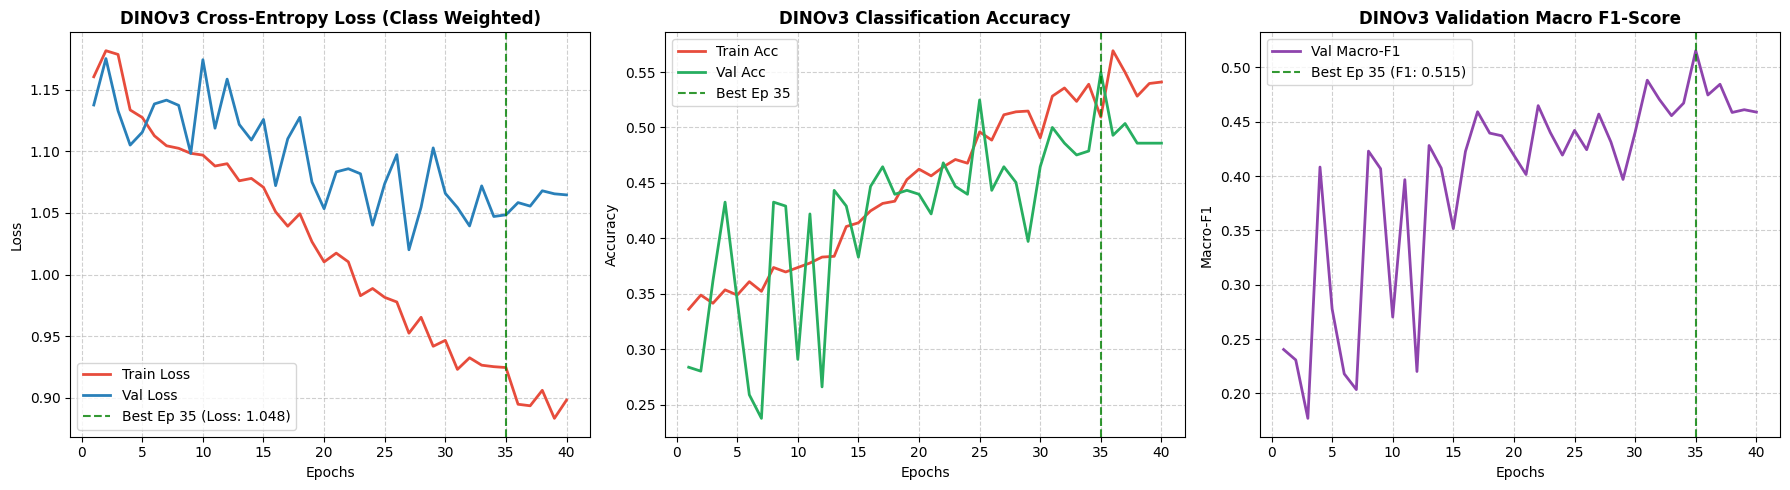

📊 Saved training curves plot at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results/dinov3_training_curves.png
💾 Saved training history CSV at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results/training_history.csv


In [33]:
# 11. Visualize Training Progress (Learning Curves saved to RESULTS_DIR)
if len(history["train_loss"]) > 0:
    epochs_range = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Loss curve
    axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", color="#e74c3c", lw=2)
    axes[0].plot(epochs_range, history["val_loss"], label="Val Loss", color="#2980b9", lw=2)
    if 'best_epoch' in locals():
        axes[0].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch} (Loss: {best_val_loss:.3f})")
    axes[0].set_title("DINOv3 Cross-Entropy Loss (Class Weighted)", fontweight="bold")
    axes[0].set_xlabel("Epochs")
    axes[0].set_ylabel("Loss")
    axes[0].legend()
    axes[0].grid(True, linestyle="--", alpha=0.6)

    # Accuracy curve
    axes[1].plot(epochs_range, history["train_acc"], label="Train Acc", color="#e74c3c", lw=2)
    axes[1].plot(epochs_range, history["val_acc"], label="Val Acc", color="#27ae60", lw=2)
    if 'best_epoch' in locals():
        axes[1].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch}")
    axes[1].set_title("DINOv3 Classification Accuracy", fontweight="bold")
    axes[1].set_xlabel("Epochs")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True, linestyle="--", alpha=0.6)

    # Macro-F1 curve
    axes[2].plot(epochs_range, history["val_f1"], label="Val Macro-F1", color="#8e44ad", lw=2)
    if 'best_epoch' in locals():
        axes[2].axvline(x=best_epoch, color="green", linestyle="--", alpha=0.8, label=f"Best Ep {best_epoch} (F1: {best_val_f1:.3f})")
    axes[2].set_title("DINOv3 Validation Macro F1-Score", fontweight="bold")
    axes[2].set_xlabel("Epochs")
    axes[2].set_ylabel("Macro-F1")
    axes[2].legend()
    axes[2].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    chart_path = os.path.join(RESULTS_DIR, "dinov3_training_curves.png")
    plt.savefig(chart_path, dpi=200)
    plt.show()
    print(f"📊 Saved training curves plot at: {chart_path}")

    # Export training history to CSV in RESULTS_DIR
    history_df = pd.DataFrame({
        "epoch": list(epochs_range),
        "train_loss": history["train_loss"],
        "val_loss": history["val_loss"],
        "train_acc": history["train_acc"],
        "val_acc": history["val_acc"],
        "val_f1": history["val_f1"]
    })
    history_csv_path = os.path.join(RESULTS_DIR, "training_history.csv")
    history_df.to_csv(history_csv_path, index=False, encoding="utf-8")
    print(f"💾 Saved training history CSV at: {history_csv_path}")


[*] 🔄 Loading separated fine-tuned DINOv3 Backbone & Classification Head from Drive...
✅ Loaded Backbone (dinov3_finetuned_backbone_best.pt) + Head (dinov3_classification_head_best.pt) from Epoch 35!


Evaluating Test Set:   0%|          | 0/19 [00:00<?, ?it/s]


🏆 DINOV3 IMAGE-LEVEL TEST EVALUATION RESULTS (TTA=ON)
  • Test Loss                 : 1.1419
  • Test Accuracy (Image-level): 38.59 %
  • Test Macro-F1 (Image-level): 0.3877

📋 [PER-CLASS CLASSIFICATION REPORT]
              precision    recall  f1-score   support

      Unripe     0.3091    0.5667    0.4000        60
        Ripe     0.3611    0.3421    0.3514       114
    Overripe     0.5250    0.3387    0.4118       124

    accuracy                         0.3859       298
   macro avg     0.3984    0.4158    0.3877       298
weighted avg     0.4188    0.3859    0.3863       298

🍈 DINOV3 FRUIT-LEVEL EVALUATION RESULTS (24 TEST FRUITS)
  • Test Accuracy (Fruit-level): 45.83 %
  • Test Macro-F1 (Fruit-level): 0.4475

💾 Saved detailed per-image predictions CSV at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results/test_predictions_detailed.csv
💾 Saved fruit-level voting predictions CSV at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/D

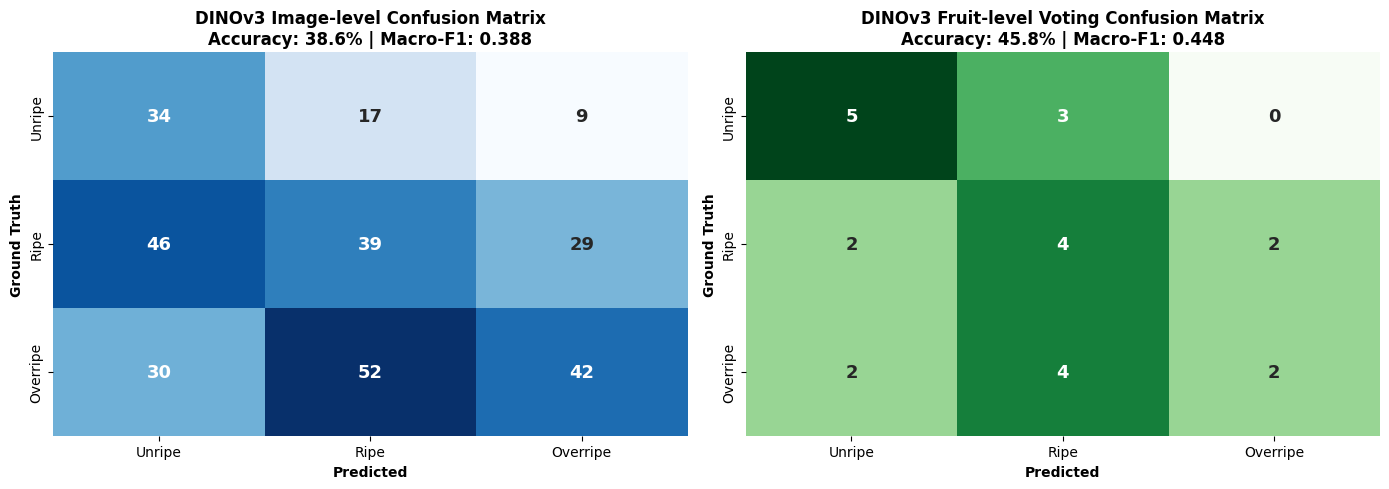

📊 Saved confusion matrices at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results/test_confusion_matrices.png

🔎 Detected 183/298 misclassified images on Test set.


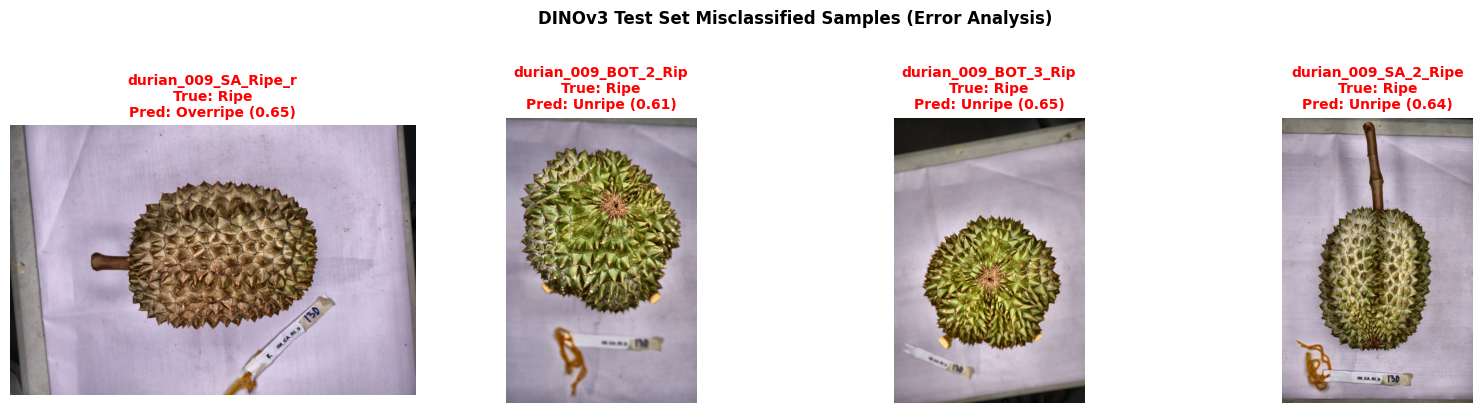

📊 Saved misclassified samples visualization at: /content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results/test_misclassified_samples.png


In [34]:
# 12. Independent Test Evaluation with Test-Time Augmentation (TTA) & Fruit-Level Voting
#     Supports loading either from the separated (Backbone + Head) .pt files or the Full Best Checkpoint.
USE_TTA = True  # Combine original + horizontal flip + slight zoom view at test time

if os.path.isfile(FINETUNED_BACKBONE_BEST_PATH) and os.path.isfile(CLASSIFICATION_HEAD_BEST_PATH):
    print(f"[*] 🔄 Loading separated fine-tuned DINOv3 Backbone & Classification Head from Drive...")
    bb_cp = torch.load(FINETUNED_BACKBONE_BEST_PATH, map_location=DEVICE)
    hd_cp = torch.load(CLASSIFICATION_HEAD_BEST_PATH, map_location=DEVICE)
    model.backbone.load_state_dict(bb_cp["backbone_state_dict"])
    model.classification_head.load_state_dict(hd_cp["classification_head_state_dict"])
    loaded_best_epoch = bb_cp.get("epoch", best_epoch)
    print(f"✅ Loaded Backbone ({os.path.basename(FINETUNED_BACKBONE_BEST_PATH)}) + Head ({os.path.basename(CLASSIFICATION_HEAD_BEST_PATH)}) from Epoch {loaded_best_epoch}!")
elif os.path.isfile(BEST_FULL_CHECKPOINT_PATH):
    print(f"[*] 🔄 Loading full best checkpoint from: {BEST_FULL_CHECKPOINT_PATH}...")
    best_cp = torch.load(BEST_FULL_CHECKPOINT_PATH, map_location=DEVICE)
    model.load_state_dict(best_cp["model_state_dict"])
    loaded_best_epoch = best_cp.get("epoch", best_epoch)
    print(f"✅ Loaded full best Checkpoint at Epoch {loaded_best_epoch} (Val Loss: {best_cp.get('best_val_loss', 0.0):.4f} | Val F1: {best_cp.get('best_val_f1', 0.0):.4f})")
else:
    loaded_best_epoch = best_epoch if 'best_epoch' in locals() else 1
    print("⚠️ Using current in-memory model weights.")

model.eval()
test_loss = 0.0
all_preds, all_targets, all_probs, all_filenames = [], [], [], []

with torch.no_grad():
    for images, targets, filenames in tqdm(test_loader, desc="Evaluating Test Set"):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        with torch.amp.autocast('cuda', enabled=(DEVICE.type == 'cuda')):
            logits_orig, _ = model(images)
            loss = criterion(logits_orig, targets)

            if USE_TTA:
                # View 2: Horizontal Flip
                logits_hflip, _ = model(torch.flip(images, dims=[3]))
                # View 3: Slight 95% Central Zoom resized back to 384x384
                pad = max(1, int(images.shape[-1] * 0.025))
                cropped = images[:, :, pad:-pad, pad:-pad]
                zoomed = F.interpolate(cropped, size=images.shape[-2:], mode="bilinear", align_corners=False)
                logits_zoom, _ = model(zoomed)

                probs_batch = (
                    0.50 * F.softmax(logits_orig, dim=1) +
                    0.30 * F.softmax(logits_hflip, dim=1) +
                    0.20 * F.softmax(logits_zoom, dim=1)
                ).cpu().numpy()
            else:
                probs_batch = F.softmax(logits_orig, dim=1).cpu().numpy()
        
        test_loss += loss.item() * images.size(0)
        preds = np.argmax(probs_batch, axis=1)
        
        all_preds.extend(preds)
        all_targets.extend(targets.cpu().numpy())
        all_probs.extend(probs_batch)
        all_filenames.extend(filenames)

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)
all_probs = np.array(all_probs)
test_loss /= len(test_loader.dataset)

# 1. IMAGE-LEVEL EVALUATION RESULTS
img_acc = accuracy_score(all_targets, all_preds)
img_macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)

print("\n" + "="*65)
print(f"🏆 DINOV3 IMAGE-LEVEL TEST EVALUATION RESULTS (TTA={'ON' if USE_TTA else 'OFF'})")
print("="*65)
print(f"  • Test Loss                 : {test_loss:.4f}")
print(f"  • Test Accuracy (Image-level): {img_acc * 100:.2f} %")
print(f"  • Test Macro-F1 (Image-level): {img_macro_f1:.4f}")
print("="*65 + "\n")

cls_report_str = classification_report(all_targets, all_preds, target_names=RIPENESS_ORDER, digits=4, zero_division=0)
cls_report_dict = classification_report(all_targets, all_preds, target_names=RIPENESS_ORDER, digits=4, zero_division=0, output_dict=True)
print("📋 [PER-CLASS CLASSIFICATION REPORT]")
print(cls_report_str)

# 2. FRUIT-LEVEL VOTING RESULTS
test_records = []
for fn, t, p, prob in zip(all_filenames, all_targets, all_preds, all_probs):
    fid = fn.split("_")[0] + "_" + fn.split("_")[1] if len(fn.split("_")) > 1 else fn
    test_records.append({
        "filename": fn,
        "fruit_id": fid,
        "true_label": RIPENESS_ORDER[t],
        "pred_label": RIPENESS_ORDER[p],
        "prob_Unripe": prob[0],
        "prob_Ripe": prob[1],
        "prob_Overripe": prob[2],
        "is_correct": bool(t == p)
    })
df_test_results = pd.DataFrame(test_records)

fruit_voting = df_test_results.groupby("fruit_id").agg({
    "true_label": "first",
    "prob_Unripe": "mean",
    "prob_Ripe": "mean",
    "prob_Overripe": "mean"
}).reset_index()

fruit_probs = fruit_voting[["prob_Unripe", "prob_Ripe", "prob_Overripe"]].values
fruit_voting["voted_label"] = [RIPENESS_ORDER[i] for i in np.argmax(fruit_probs, axis=1)]
fruit_y_true = fruit_voting["true_label"].map(LABEL_TO_IDX)
fruit_y_pred = fruit_voting["voted_label"].map(LABEL_TO_IDX)

fruit_acc = accuracy_score(fruit_y_true, fruit_y_pred)
fruit_macro_f1 = f1_score(fruit_y_true, fruit_y_pred, average="macro", zero_division=0)

print("="*65)
print(f"🍈 DINOV3 FRUIT-LEVEL EVALUATION RESULTS ({len(fruit_voting)} TEST FRUITS)")
print("="*65)
print(f"  • Test Accuracy (Fruit-level): {fruit_acc * 100:.2f} %")
print(f"  • Test Macro-F1 (Fruit-level): {fruit_macro_f1:.4f}")
print("="*65 + "\n")

# Save detailed image-level and fruit-level CSVs + JSON summary in RESULTS_DIR
csv_test_path = os.path.join(RESULTS_DIR, "test_predictions_detailed.csv")
df_test_results.to_csv(csv_test_path, index=False, encoding="utf-8")
print(f"💾 Saved detailed per-image predictions CSV at: {csv_test_path}")

csv_fruit_path = os.path.join(RESULTS_DIR, "test_fruit_level_voting.csv")
fruit_voting.to_csv(csv_fruit_path, index=False, encoding="utf-8")
print(f"💾 Saved fruit-level voting predictions CSV at: {csv_fruit_path}")

metrics_summary = {
    "model": f"DINOv3 ({model.model_name}) + Classification Head",
    "feature_dim": int(model.num_features),
    "image_size": IMAGE_SIZE,
    "use_tta": USE_TTA,
    "best_epoch": int(loaded_best_epoch),
    "test_loss": float(test_loss),
    "image_level_accuracy": float(img_acc),
    "image_level_macro_f1": float(img_macro_f1),
    "fruit_level_accuracy": float(fruit_acc),
    "fruit_level_macro_f1": float(fruit_macro_f1),
    "total_test_images": int(len(df_test_results)),
    "total_test_fruits": int(len(fruit_voting)),
    "classification_report": cls_report_dict,
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")
}
json_summary_path = os.path.join(RESULTS_DIR, "test_metrics_summary.json")
with open(json_summary_path, "w", encoding="utf-8") as f:
    json.dump(metrics_summary, f, indent=2, ensure_ascii=False)
print(f"💾 Saved test metrics summary JSON at: {json_summary_path}")

# 3. PLOT SIDE-BY-SIDE CONFUSION MATRICES
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm_img = confusion_matrix(all_targets, all_preds)
sns.heatmap(cm_img, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=RIPENESS_ORDER, yticklabels=RIPENESS_ORDER, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[0].set_title(f"DINOv3 Image-level Confusion Matrix\nAccuracy: {img_acc*100:.1f}% | Macro-F1: {img_macro_f1:.3f}", fontweight="bold")
axes[0].set_xlabel("Predicted", fontweight="bold")
axes[0].set_ylabel("Ground Truth", fontweight="bold")

cm_fruit = confusion_matrix(fruit_y_true, fruit_y_pred)
sns.heatmap(cm_fruit, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=RIPENESS_ORDER, yticklabels=RIPENESS_ORDER, cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[1].set_title(f"DINOv3 Fruit-level Voting Confusion Matrix\nAccuracy: {fruit_acc*100:.1f}% | Macro-F1: {fruit_macro_f1:.3f}", fontweight="bold")
axes[1].set_xlabel("Predicted", fontweight="bold")
axes[1].set_ylabel("Ground Truth", fontweight="bold")

plt.tight_layout()
cm_fig_path = os.path.join(RESULTS_DIR, "test_confusion_matrices.png")
plt.savefig(cm_fig_path, dpi=200)
plt.show()
print(f"📊 Saved confusion matrices at: {cm_fig_path}")

# 4. VISUALIZE MISCLASSIFIED SAMPLES
misclassified = df_test_results[~df_test_results["is_correct"]]
print(f"\n🔎 Detected {len(misclassified)}/{len(df_test_results)} misclassified images on Test set.")
if len(misclassified) > 0:
    sample_errors = misclassified.head(min(4, len(misclassified)))
    fig, axes = plt.subplots(1, len(sample_errors), figsize=(4 * len(sample_errors), 4))
    if len(sample_errors) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, sample_errors.iterrows()):
        img_path = None
        for sp_item in image_splits["test"]:
            if sp_item["filename"] == row["filename"]:
                img_path = sp_item["filepath"]
                break
        if img_path and os.path.isfile(img_path):
            disp_img = cv2.imread(img_path)
            disp_img = cv2.cvtColor(disp_img, cv2.COLOR_BGR2RGB)
            ax.imshow(disp_img)
        ax.set_title(f"{row['filename'][:20]}\nTrue: {row['true_label']}\nPred: {row['pred_label']} ({row[f'prob_{row["pred_label"]}']:.2f})",
                     color="red", fontsize=10, fontweight="bold")
        ax.axis("off")
    plt.suptitle("DINOv3 Test Set Misclassified Samples (Error Analysis)", fontweight="bold", y=1.02)
    plt.tight_layout()
    err_path = os.path.join(RESULTS_DIR, "test_misclassified_samples.png")
    plt.savefig(err_path, dpi=200, bbox_inches="tight")
    plt.show()
    print(f"📊 Saved misclassified samples visualization at: {err_path}")


## 🎯 Summary of Non-Overwriting Checkpoints & Test Artifacts

1. **Checkpoints (`/content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/checkpoint`):**
   - **`dinov3_pretrained_raw_weights.pt`**: Cached raw pretrained DINOv3 backbone weights (downloaded once, reloaded offline on subsequent runs to save time).
   - **`dinov3_finetuned_backbone_best.pt`**: Best fine-tuned DINOv3 visual feature backbone.
   - **`dinov3_classification_head_best.pt`**: Best trained Classification Head weights (kept completely separate from the backbone `.pt` files).
   - **`dinov3_full_model_best.pt`** & **`dinov3_full_model_last.pt`**: Complete training state checkpoints.
   - **`dinov3_periodic_epoch_XX.pt`**: Periodic snapshots saved every 5 epochs.
2. **Test Results (`/content/drive/MyDrive/durian-ripeness-cmkd/baselines/DINOV3_classification_head/results`):**
   - **`test_predictions_detailed.csv`** & **`test_fruit_level_voting.csv`**
   - **`test_metrics_summary.json`** & **`training_history.csv`**
   - **`dinov3_training_curves.png`**, **`test_confusion_matrices.png`**, and **`test_misclassified_samples.png`**